<a href="https://colab.research.google.com/github/chenharry66/adversial-audio-experiments/blob/main/perturbation_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Setup

In [56]:
#install depencies
!pip install werpy scipy

In [57]:
# import dependncies
import werpy, torch

In [58]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
from scipy.io import wavfile

rate, data = wavfile.read('/content/drive/MyDrive/FOLDER/01/recording2.wav')

data.dtype

dtype('int16')

In [60]:
clip = data[:160000]

In [61]:
import numpy as np

clip = clip / 32768

In [62]:
def pad_to_target_duration(waveform, duration):
    target = int(duration * rate)
    numToPad = max(0, target - len(waveform))
    waveform = waveform + ([0] * numToPad)
    return waveform

In [96]:
from IPython.display import Audio

audio = Audio(data = clip, rate = rate, normalize=True)
audio

##Model Definition and Establishing a Baseline

We now have our target audio. We will then initialize our frozen ASR model. Eventually after breaking whisper tiny, we can scale to more complex architectures.

In [64]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

In [65]:
input_features = processor(clip, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)

In [66]:
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)

In [67]:
transcription =  "".join(transcription)

In [68]:
reference = "I must make an admission,” Ivan began. “I never could understand how it’s ‘possible to love one’s neighbors"

In [69]:
import regex as re

def custom_normalize(text):
    clean_text = re.sub(r'[\p{P}\p{S}]', '', text)
    return werpy.normalize(clean_text)

In [70]:
reference = custom_normalize(reference)
transcription = custom_normalize(transcription)

In [71]:
wer = werpy.wer(reference, transcription)
print(f"Baseline Wer: {wer * 100:.2f}%")

Baseline Wer: 33.33%


Our baseline WER measurement is 33%.



## Perturbial Optimization within Whole Audio Timeframe

We can think of perturbial generation as a naive constrained optimization problem, where we are optimizing against some differentiable loss function (in this case we define that loss funciton to be CTC loss) and our constraint is that the SNR for the clip has to be under some limit. From previous experiments,**we define that SNR to be 23dB initially.** We can think of our adverserial perturbation δ as essentially an array of weights where each weight **$w_t$ represents the amplitude of the waveform at time t.** For each iteration of training, we take our initial audio waveform $x$, add $\delta$ to it, and transcribe the result using our frozen model. And then we backpropogate, moving in direction of the loss function's gradient, taking a PGD like approach where we clip back to the boundrayr whenever the SNR exceeds our limit.

In [72]:
audio_rms = np.sqrt(np.mean(clip ** 2))

In [73]:
audio_rms = np.float32(audio_rms)

In [74]:
audio_rms

np.float32(0.00611138)

In [75]:
target_rms = audio_rms/(10**(23/20))

In [76]:
 20 * np.log10(audio_rms/target_rms)

np.float32(23.0)

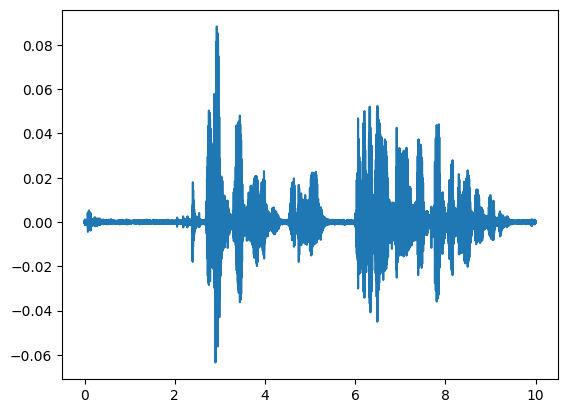

In [77]:
import matplotlib.pyplot as plt

t = np.linspace(0, 10, int(rate * 10), endpoint=False)
plt.plot(t, clip)

In [78]:
clip = pad_to_target_duration(clip.tolist(),30)

In [79]:
from torch import stft

MAX_ITERS = 200
ALPHA = 1e-5

clip = torch.tensor(clip)
delta = torch.zeros_like(clip, requires_grad=True)

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for p in model.parameters():
    p.requires_grad = False

for i in range(MAX_ITERS):
    delta.grad = None
    # forward pass compute the perturbation and then get the feature feed htrough asr
    perturbation = clip + delta
    window = torch.hann_window(400)
    stft = torch.stft(perturbation, 400, 160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.from_numpy(processor.feature_extractor.mel_filters).float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    out = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")
    loss = out.loss
    print(f"Iteration {i} Loss: {loss.item()}")
    # backward
    loss.backward()
    # update
    with torch.no_grad():
        delta += ALPHA * delta.grad
        current_rms = torch.sqrt(torch.mean(delta**2)) + 1e-6
        print(f"Iteration {i} RMS: {current_rms}")
        if current_rms > target_rms:
            delta *= (target_rms / current_rms)

Iteration 0 Loss: 4.937741279602051
Iteration 0 RMS: 1.1763266229536384e-05
Iteration 1 Loss: 6.224283218383789
Iteration 1 RMS: 1.768281617842149e-05
Iteration 2 Loss: 6.928654193878174
Iteration 2 RMS: 2.0122435671510175e-05
Iteration 3 Loss: 6.978845119476318
Iteration 3 RMS: 3.081002796534449e-05
Iteration 4 Loss: 7.11383056640625
Iteration 4 RMS: 3.2041018130257726e-05
Iteration 5 Loss: 7.944899082183838
Iteration 5 RMS: 3.265352643211372e-05
Iteration 6 Loss: 8.586910247802734
Iteration 6 RMS: 3.380258203833364e-05
Iteration 7 Loss: 8.862380027770996
Iteration 7 RMS: 3.43563333444763e-05
Iteration 8 Loss: 9.147446632385254
Iteration 8 RMS: 3.492682662908919e-05
Iteration 9 Loss: 9.443381309509277
Iteration 9 RMS: 3.5555363865569234e-05
Iteration 10 Loss: 9.723751068115234
Iteration 10 RMS: 3.62448045052588e-05
Iteration 11 Loss: 9.985894203186035
Iteration 11 RMS: 3.701596142491326e-05
Iteration 12 Loss: 10.086977005004883
Iteration 12 RMS: 3.893794200848788e-05
Iteration 13 Loss

In [80]:
delta = delta.detach().numpy()
clip = clip.detach().numpy()

In [81]:
aug_audio = clip + delta

In [82]:
#inference (can copy this over for winowed-timefframe alter)
inputs = processor(aug_audio, return_tensors="pt", sampling_rate=rate)
generated_ids = model.generate(input_features=inputs['input_features'])
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
transcription = custom_normalize(transcription)
wer = werpy.wer(reference, transcription)

In [83]:
print(f"Wer: {wer * 100}%")

Wer: 116.66666666666667%


In [84]:
20 * np.log10(np.sqrt(np.mean(clip**2))/np.sqrt(np.mean(delta**2)))

np.float32(25.677086)

In [30]:
Audio(aug_audio, rate=rate)

## Perturbial Optimization Within Windowed-Timeframes

In [44]:
# 20 buckets for target rms
# iterate over the original array
target_rms = []

for i in range(0, len(clip), 8000):
    # this ur target_rms
    rms = np.sqrt(np.mean(clip[i: i+8000]**2))/10**(23/20)
    target_rms.append(rms)

In [46]:
from torch import stft

MAX_ITERS = 200
ALPHA = 1e-5

clip = torch.tensor(clip)
delta = torch.zeros_like(clip, requires_grad=True)
target_rms = torch.tensor(target_rms)

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for p in model.parameters():
    p.requires_grad = False

for i in range(MAX_ITERS):
    delta.grad=None
    # forward pass compute the perturbation and then get the feature feed htrough asr
    perturbation = clip + delta
    window = torch.hann_window(400)
    stft = torch.stft(perturbation, 400, 160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.from_numpy(processor.feature_extractor.mel_filters).float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    out = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")
    loss = out.loss

    print(f"Iteration {i} Loss: {loss.item()}")
    # backward
    loss.backward()
    # update
    with torch.no_grad():
        for j in range(0, len(perturbation), 8000):
            delta[j:j+8000] += ALPHA * delta.grad[j:j+8000]
            current_rms = torch.sqrt(torch.mean(delta[j:j+8000]**2)) + 1e-6
            print(f"Iteration {i}, Group {j//8000} RMS: {current_rms}")
            if current_rms > target_rms[j//8000]:
                delta[j:j+8000]*= (target_rms[j//8000]/ current_rms)

/tmp/ipykernel_2464/1033109829.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  clip = torch.tensor(clip)


Streaming output truncated to the last 5000 lines.
Iteration 118, Group 1 RMS: 0.0007463116780854762
Iteration 118, Group 2 RMS: 0.001106180832721293
Iteration 118, Group 3 RMS: 0.0002798383357003331
Iteration 118, Group 4 RMS: 0.00041870103450492024
Iteration 118, Group 5 RMS: 0.0010253791697323322
Iteration 118, Group 6 RMS: 0.0006710630259476602
Iteration 118, Group 7 RMS: 0.0005132013466209173
Iteration 118, Group 8 RMS: 0.0003762280393857509
Iteration 118, Group 9 RMS: 0.0005382645758800209
Iteration 118, Group 10 RMS: 0.00044909375719726086
Iteration 118, Group 11 RMS: 0.00028274135547690094
Iteration 118, Group 12 RMS: 0.0009429482161067426
Iteration 118, Group 13 RMS: 0.0007832547998987138
Iteration 118, Group 14 RMS: 0.0006206264370121062
Iteration 118, Group 15 RMS: 0.0005612915265373886
Iteration 118, Group 16 RMS: 0.0007756007835268974
Iteration 118, Group 17 RMS: 0.000740149465855211
Iteration 118, Group 18 RMS: 0.00046546931844204664
Iteration 118, Group 19 RMS: 0.0016660

In [47]:
delta = delta.detach().numpy()
clip = clip.detach().numpy()

In [48]:
import random

options = np.arange(0, len(clip), 8000)
options

num = random.randint(0, len(options)-1)
start_index = options[num]
print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/(np.sqrt(np.mean(delta[start_index:start_index+8000]**2)) + 1e-6)))

num = random.randint(0, len(options))
start_index = options[num]

print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/((np.sqrt(np.mean(delta[start_index:start_index+8000]**2))) +1e-6)))

-inf
-inf


/tmp/ipykernel_2464/3195939163.py:8: RuntimeWarning: divide by zero encountered in log10
  print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/(np.sqrt(np.mean(delta[start_index:start_index+8000]**2)) + 1e-6)))
/tmp/ipykernel_2464/3195939163.py:13: RuntimeWarning: divide by zero encountered in log10
  print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/((np.sqrt(np.mean(delta[start_index:start_index+8000]**2))) +1e-6)))


In [49]:
aug_audio = clip + delta

In [50]:
#inference (can copy this over for winowed-timefframe alter)
inputs = processor(aug_audio, return_tensors="pt", sampling_rate=rate)
generated_ids = model.generate(input_features=inputs['input_features'])
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
transcription = custom_normalize(transcription)
wer = werpy.wer(reference, transcription)

In [51]:
print(f"Wer: {wer * 100}%")

Wer: 105.55555555555556%


In [52]:
Audio(aug_audio, rate=rate)

Good wer, but can still hear the prickly noise. Lets see if we can make it practically invisible

## Psychoacoustic Perturbial Optimizations

We use Qin et al., 2019's approach to calculate a global threshold for audibility for each frequency bin. And then we add an additional penalty $ l_{theta} $ which uses hinge loss based on that threshold.

In [30]:
!pip install --upgrade "numba==0.68.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 8.1 MB/s eta 0:00:00
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.44.0
    Uninstalling llvmlite-0.44.0:
      Successfully uninstalled llvmlite-0.44.0
  Attempting uninstall: numba
    Found existing installation: numba 0.61.2
    Uninstalling numba-0.61.2:
      Successfully uninstalled numba-0.61.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.0 which is incompatible.


In [31]:
!pip install librosa

In [85]:
# so now i want to look at how i can make this perturbation inaudible
import sys
sys.path.append("/content/drive/MyDrive/FOLDER/01")
import generate_masking_threshold as masking

theta_xs, psd_max = masking.generate_th(clip, rate, window_size=2048)

#ened a function to calculate the normalized psds for the pertubration since we need it to be backpropable


In [86]:
theta_xs

array([[5.04803786e+03, 8.15711637e+03, 1.31812479e+04, ...,
        9.13634015e+01, 8.83349217e+01, 8.54113417e+01],
       [2.14499314e+03, 3.46609102e+03, 5.60092597e+03, ...,
        9.04083486e+01, 8.74340468e+01, 8.45620578e+01],
       [4.14863983e+02, 6.70378052e+02, 1.08327734e+03, ...,
        2.01498634e+02, 1.95319646e+02, 1.89339899e+02],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        1.88573721e-01, 1.89243156e-01, 1.89917054e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        1.88573721e-01, 1.89243156e-01, 1.89917054e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        1.88573721e-01, 1.89243156e-01, 1.89917054e-01]],
      shape=(934, 1025))

In [87]:
import librosa

def compute_PSD_for_perturbation(perturbation, psd_max, window_size):
    win = torch.hann_window(window_size)
    spectrum = torch.stft(perturbation, window=win, n_fft = window_size, hop_length=window_size//4, onesided=True, center=False, return_complex=True)
    z = torch.sqrt(torch.tensor(8 / 3)) * torch.abs(spectrum / window_size)
    psd = 10 * torch.log10(z * z + 0.0000000000000000001)
    PSD = 96 - 10 * torch.log10(psd_max + 0.0000000000000000001) + psd
    PSD = 10**(PSD/10)
    return PSD.T
    # frequency bin and time frames

In [88]:
def compute_mask_threshold_loss(psd_perturb, theta_xs):
    average_loss_per_frame = torch.mean((psd_perturb - theta_xs).relu(), dim=1)
    return torch.mean(average_loss_per_frame)

Take the delta from last step and then perform trianign with the new penalty

In [91]:
from torch import stft

MAX_ITERS = 200
ALPHA = 1e-5
BETA = 0.5

clip = torch.tensor(clip)
delta = torch.tensor(delta, requires_grad=True)
theta_xs = torch.tensor(theta_xs)
window_size = 2048
psd_max = torch.tensor(psd_max)

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for p in model.parameters():
    p.requires_grad = False

for i in range(MAX_ITERS):
    delta.grad=None
    # forward pass compute the perturbation and then get the feature feed htrough asr
    perturbation = clip + delta
    window = torch.hann_window(400)
    stft = torch.stft(perturbation, 400, 160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.from_numpy(processor.feature_extractor.mel_filters).float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    out = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")

    psd_perturb = compute_PSD_for_perturbation(delta, psd_max, window_size)


    mask_loss = compute_mask_threshold_loss(psd_perturb, theta_xs)
    # so we're maximizing the loss so to minimze the mask threhosld loss we subtract here
    print(f"mask loss: {mask_loss.item()}")
    loss = out.loss - BETA * mask_loss
    print(f"Iteration {i} Loss: {loss.item()}")
    # backward
    loss.backward()
    # update
    with torch.no_grad():
        delta += ALPHA * delta.grad

/tmp/ipykernel_743/3840899584.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  clip = torch.tensor(clip)
/tmp/ipykernel_743/3840899584.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  delta = torch.tensor(delta, requires_grad=True)
/tmp/ipykernel_743/3840899584.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta_xs = torch.tensor(theta_xs)
/tmp/ipykernel_743/3840899584.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True

mask loss: 748.622547943655
Iteration 0 Loss: -353.3272823489027
mask loss: 104.9603485568066
Iteration 1 Loss: -40.68577120223142
mask loss: 50.160794189505424
Iteration 2 Loss: -15.04653116610281
mask loss: 16.89462054005053
Iteration 3 Loss: 2.4342691290836225
mask loss: 10.900529224529242
Iteration 4 Loss: 6.064085325174344
mask loss: 7.5677058678747695
Iteration 5 Loss: 7.250569940513299
mask loss: 22.251060888591155
Iteration 6 Loss: 0.14293269047004742
mask loss: 13.324985014362769
Iteration 7 Loss: 4.352780586995862
mask loss: 19.761999965822458
Iteration 8 Loss: 1.1481967562855484
mask loss: 15.764623236667925
Iteration 9 Loss: 3.467970097059104
mask loss: 8.880452160803683
Iteration 10 Loss: 7.465828416363295
mask loss: 13.791610636695063
Iteration 11 Loss: 4.174609224804324
mask loss: 30.413067075638654
Iteration 12 Loss: -3.681591139748038
mask loss: 29.085739330723094
Iteration 13 Loss: -2.269963361955785
mask loss: 10.974182604646009
Iteration 14 Loss: 6.74042010362182
ma

In [93]:
delta = delta.detach().numpy()
clip = clip.detach().numpy()

In [94]:
aug_audio = delta + clip

In [97]:
Audio(aug_audio, rate=rate, normalize=True)

In [98]:
inputs = processor(aug_audio, sampling_rate=rate, return_tensors="pt")

In [99]:
generated_ids = model.generate(inputs['input_features'])

In [101]:
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
transcription = custom_normalize(transcription)
transcription

'by most the day the amount of it can mock me with them i never go more stand how possible its local instinct moves freely'

In [102]:
wer = werpy.wer(reference, transcription)

In [103]:
print(f"Wer: {wer*100} %")

Wer: 122.22222222222223 %


That's pretty fucking cool. If you compare to the first recording. Sounds almost the same, but the transcription error is like 90% more.